In [54]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
from stable_baselines3 import PPO

class Vehicle:
    """内部辅助类：记录单辆车的物理状态和性格参数"""
    def __init__(self, x, v, is_av, is_ego, T, a):
        self.x = x              # 位置
        self.v = v              # 速度
        self.is_av = is_av      # 是否为自动驾驶车辆
        self.is_ego = is_ego    # 是否为当前受 RL 控制的“主角”
        self.T = T              # 安全时距 (性格)
        self.a = a              # 最大加速度 (性格)
        self.b = 1.5            # 舒适减速度
        self.s0 = 2.0           # 最小安全间距
        self.v0 = 15.0          # 期望速度 (约 54 km/h)

class OpenTrafficEnv(gym.Env):
    """
    单车道开放系统交通流环境 (Gymnasium API)
    用于训练单个 Ego AV 的连续跟驰策略
    """
    def __init__(self, road_length=500.0, dt=0.5, av_ratio=0.2):
        super(OpenTrafficEnv, self).__init__()
        self.road_length = road_length
        self.dt = dt
        self.av_ratio = av_ratio
        
        # 动作空间：连续加速度 [-3.0, 2.0]
        self.action_space = spaces.Box(low=-3.0, high=2.0, shape=(1,), dtype=np.float32)
        
        # 状态空间：5 维向量 [v_ego, s_lead, dv_lead, s_av, v_av]
        self.observation_space = spaces.Box(low=-100.0, high=self.road_length, shape=(7,), dtype=np.float32)
        
        self.vehicles = []
        self.time_to_next_spawn = 0.0
        self.step_count = 0
        self.max_steps = 1000  # 防止死循环的截断步数

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.vehicles = []
        self.step_count = 0
        
        # 预填充道路 (Pre-populate) 以免主角一开始在空路上跑
        # 在道路前方随机散布一些人类车辆
        for x in range(50, int(self.road_length - 50), 30):
            if np.random.rand() > 0.3: # 70%概率放置车辆
                v = np.random.normal(10.0, 2.0)
                T = np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
                self.vehicles.append(Vehicle(x, v, is_av=False, is_ego=False, T=T, a=1.0))
                
        # 在道路起点 (x=0) 生成我们的“主角” Ego AV
        self.ego_veh = Vehicle(x=0.0, v=10.0, is_av=True, is_ego=True, T=1.0, a=1.5)
        self.vehicles.append(self.ego_veh)
        
        # 确保车辆按位置从远到近(降序)排序
        self.vehicles.sort(key=lambda v: v.x, reverse=True)
        self.time_to_next_spawn = np.random.exponential(1.2)
        
        return self._get_obs(), {}

    def _get_obs(self):
        v_ego = self.ego_veh.v
        s_lead, dv_lead = 100.0, 0.0
        s_lag, v_lag = 100.0, self.ego_veh.v0 # 新增：后车距离和速度
        s_av, v_av = 100.0, 15.0
        
        ego_idx = self.vehicles.index(self.ego_veh)
        
        # 向前看 (Lead)
        if ego_idx > 0:
            lead_veh = self.vehicles[ego_idx - 1]
            s_lead = min(lead_veh.x - self.ego_veh.x, 100.0)
            dv_lead = self.ego_veh.v - lead_veh.v
            
            for i in range(ego_idx - 1, -1, -1):
                if self.vehicles[i].is_av:
                    s_av = min(self.vehicles[i].x - self.ego_veh.x, 100.0)
                    v_av = self.vehicles[i].v
                    break
                    
        # 向后看 (Lag) - 极其重要！
        if ego_idx < len(self.vehicles) - 1:
            lag_veh = self.vehicles[ego_idx + 1]
            s_lag = min(self.ego_veh.x - lag_veh.x, 100.0)
            v_lag = lag_veh.v
        
        norm_v_ego = v_ego / 15.0
        norm_s_lead = s_lead / 100.0
        # 速度差 dv_lead 范围大概在 [-15, 15]，映射到 [0, 1]
        norm_dv_lead = (dv_lead + 15.0) / 30.0 
        norm_s_lag = s_lag / 100.0
        norm_v_lag = v_lag / 15.0
        norm_s_av = s_av / 100.0
        norm_v_av = v_av / 15.0

        return np.array([norm_v_ego, norm_s_lead, norm_dv_lead, norm_s_lag, norm_v_lag, norm_s_av, norm_v_av], dtype=np.float32)

    def step(self, action):
        self.step_count += 1
        accelerations = []
        aeb_penalty = 0.0
        
        # 1. 泊松车流生成 (在起点 x=0 之后伺机生成新车)
        self.time_to_next_spawn -= self.dt
        if self.time_to_next_spawn <= 0:
            last_veh = self.vehicles[-1]
            # 如果起点有足够的空隙 (> 20米)，才生成新车
            if last_veh.x > 10.0:
                is_av = np.random.rand() < self.av_ratio
                T = 1.0 if is_av else np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
                new_veh = Vehicle(x=0.0, v=15.0, is_av=is_av, is_ego=False, T=T, a=1.0)
                self.vehicles.append(new_veh)
                self.time_to_next_spawn = np.random.exponential(1.2)
        
        # 2. 计算所有车辆的加速度
        for i, veh in enumerate(self.vehicles):
            s = 999.0
            dv = 0.0
            if i > 0: # 前方有车
                lead_veh = self.vehicles[i - 1]
                s = lead_veh.x - veh.x
                dv = veh.v - lead_veh.v
                
            if veh.is_ego:
                # ==================================
                # 主角 (Ego AV) - 强化学习动作与 AEB 护盾
                # ==================================
                acc = action[0]
                critical_dist = 2.0 + veh.v * 0.8
                if s < critical_dist:
                    acc = -4.0
                    aeb_penalty = -5.0 # 触发安全护盾，重罚
            else:
                # ==================================
                # 其他车辆 (HV & 非主角AV) - IDM 模型
                # ==================================
                s_star = veh.s0 + veh.v * veh.T + (veh.v * dv) / (2 * np.sqrt(veh.a * veh.b))
                s_star = max(s_star, veh.s0)
                acc = veh.a * (1 - (veh.v / veh.v0)**4 - (s_star / max(s, 0.1))**2)
                
                # 物理防穿模
                if s < veh.s0:
                    acc = -4.0
                acc = np.clip(acc, -4.0, 2.0)
                
            accelerations.append(acc)
            
        # 3. 更新物理状态
        for i, veh in enumerate(self.vehicles):
            veh.v += accelerations[i] * self.dt
            veh.v = np.clip(veh.v, 0.0, veh.v0) # 防止倒车，限制极速
            veh.x += veh.v * self.dt
            
        # 4. 清理驶出道路的车辆，并更新排序
        self.vehicles = [v for v in self.vehicles if v.x < self.road_length]
        self.vehicles.sort(key=lambda v: v.x, reverse=True)
        
        # 5. 判断结束条件 (Terminated/Truncated)
        terminated = False
        # 如果 Ego AV 成功驶离道路，结束回合
        if self.ego_veh not in self.vehicles:
            terminated = True
            
        truncated = self.step_count >= self.max_steps
        
        # 6. 计算局部平滑奖励 (Reward)
# ==========================================
        # 终极修复：治愈“极度保守”的自动驾驶策略
        # ==========================================
        reward = 0.0
        if not terminated:
            # 获取后车速度（如果没有后车，默认为期望速度）
            v_lag = 15.0
            ego_idx = self.vehicles.index(self.ego_veh)
            if ego_idx < len(self.vehicles) - 1:
                v_lag = self.vehicles[ego_idx + 1].v
                
            # 动作平滑惩罚 (禁止猛踩刹车)
            action_penalty = -0.1 * (action[0] ** 2)
            
            # 50% 靠自己跑得快，50% 靠带起后车的速度
            reward = 0.5 * (self.ego_veh.v / 15.0) + 0.5 * (v_lag / 15.0) + action_penalty + aeb_penalty
        else:
            reward += 20.0

        # SB3 的新 API 要求返回 5 个值
        return self._get_obs() if not terminated else np.zeros(5, dtype=np.float32), reward, terminated, truncated, {}

# ==========================================
# 训练与测试启动脚本
# ==========================================
if __name__ == "__main__":
    env = OpenTrafficEnv()
    
    print("开始训练 PPO 模型，预计需要 30 秒 - 1 分钟...")
    model = PPO("MlpPolicy", env, verbose=1, learning_rate=5e-4)
    # 训练 20,000 步作为初始验证 (期末跑数据建议 100,000 步起)
    model.learn(total_timesteps=100000)
    print("模型训练完成！")
    
    # 保存模型以便 Deliverable 使用
    model.save("ppo_av_platooning")
    
    print("测试一轮模型...")
    obs, info = env.reset()
    total_reward = 0
    while True:
        action, _states = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        if terminated or truncated:
            break
            
    print(f"单轮测试总奖励: {total_reward:.2f}")

开始训练 PPO 模型，预计需要 30 秒 - 1 分钟...
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 132      |
|    ep_rew_mean     | 74.3     |
| time/              |          |
|    fps             | 5897     |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 109         |
|    ep_rew_mean          | 75.3        |
| time/                   |             |
|    fps                  | 5071        |
|    iterations           | 2           |
|    time_elapsed         | 0           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.006716401 |
|    clip_fraction        | 0.0847      |
|    clip_range           | 0.

Running Baseline (0% AV)...
Running RL Intervention (20% AV)...


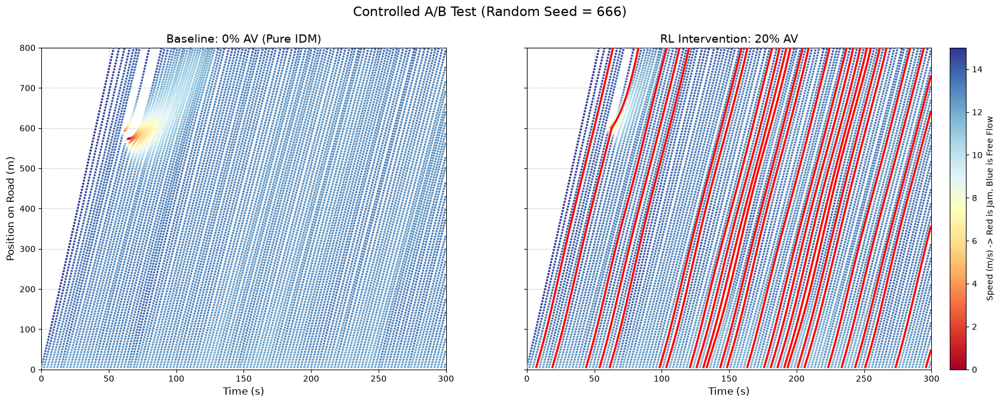

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO

# 提取局部状态的辅助函数
def get_av_obs(veh, all_vehicles, road_length):
    v_ego = veh.v
    s_lead, dv_lead = 100.0, 0.0
    s_av, v_av = 100.0, 15.0
    s_lag, v_lag = 100.0, veh.v0 # 新增：后车距离和速度
    
    idx = all_vehicles.index(veh)
    if idx > 0:
        lead_veh = all_vehicles[idx - 1]
        s_lead = min(lead_veh.x - veh.x, 100.0)
        dv_lead = veh.v - lead_veh.v
        
        for i in range(idx - 1, -1, -1):
            if all_vehicles[i].is_av:
                s_av = min(all_vehicles[i].x - veh.x, 100.0)
                v_av = all_vehicles[i].v
                break
    if idx < len(all_vehicles) - 1:
            lag_veh = all_vehicles[idx + 1]
            s_lag = min(veh.x - lag_veh.x, 100.0)
            v_lag = lag_veh.v

    norm_v_ego = v_ego / 15.0
    norm_s_lead = s_lead / 100.0
    # 速度差 dv_lead 范围大概在 [-15, 15]，映射到 [0, 1]
    norm_dv_lead = (dv_lead + 15.0) / 30.0 
    norm_s_lag = s_lag / 100.0
    norm_v_lag = v_lag / 15.0
    norm_s_av = s_av / 100.0
    norm_v_av = v_av / 15.0

    return np.array([norm_v_ego, norm_s_lead, norm_dv_lead, norm_s_lag, norm_v_lag, norm_s_av, norm_v_av], dtype=np.float32)

class Vehicle:
    def __init__(self, id, x, v, is_av, T, a):
        self.id = id; self.x = x; self.v = v; self.is_av = is_av
        self.T = T; self.a = a; self.b = 1.5; self.s0 = 2.0; self.v0 = 15.0
        self.history_t = []; self.history_x = []; self.history_v = []

def run_simulation(model, av_ratio, seed, steps=600, dt=0.5, road_length=800.0):
    """封装好的确定性物理仿真引擎"""
    np.random.seed(seed) # 【关键1】固定全局随机种子
    
    vehicles = []
    finished_vehicles = []
    veh_counter = 0
    time_to_spawn = 0.0
    
    for t in range(steps):
        current_time = t * dt
        
        # 泊松车流生成
        time_to_spawn -= dt
        if time_to_spawn <= 0 and (len(vehicles) == 0 or vehicles[-1].x > 25.0):
            rand_T = np.clip(np.random.normal(1.5, 0.3), 0.8, 2.5)
            rand_a = np.clip(np.random.normal(1.0, 0.2), 0.5, 1.5)
            
            # 【核心修改】：改成极其紧凑的均匀分布，每 0.8 到 1.0 秒强行塞入一辆车
            # 这会把道路逼入绝境，纯人类车队必然会彻底崩盘
            next_spawn = np.random.uniform(0.8, 1.0)
            
            is_av = np.random.rand() < av_ratio
            
            # 如果是 AV，覆盖性格参数；如果是 HV，使用刚才生成的随机性格
            T = 1.0 if is_av else rand_T
            a = 1.0 if is_av else rand_a
            
            new_veh = Vehicle(id=veh_counter, x=0.0, v=12.0, is_av=is_av, T=T, a=a)
            vehicles.append(new_veh)
            veh_counter += 1
            time_to_spawn = next_spawn 
            
        accelerations = []
        
        for i, veh in enumerate(vehicles):
            s, dv = 999.0, 0.0
            if i > 0:
                lead_veh = vehicles[i - 1]
                s = lead_veh.x - veh.x
                dv = veh.v - lead_veh.v
                
            critical_dist = 2.0 + veh.v * 0.8
            
            if veh.is_av and model is not None:
                obs = get_av_obs(veh, vehicles, road_length)
                action, _ = model.predict(obs, deterministic=True)
                acc = action[0]
                if s < critical_dist: acc = -4.0
            else:
                s_star = veh.s0 + veh.v * veh.T + (veh.v * dv) / (2 * np.sqrt(veh.a * veh.b))
                s_star = max(s_star, veh.s0)
                acc = veh.a * (1 - (veh.v / veh.v0)**4 - (s_star / max(s, 0.1))**2)
                if s < veh.s0: acc = -4.0
                acc = np.clip(acc, -4.0, 2.0)
                
            # 【制造交通拥堵】第 60-65 秒，让道路中间靠前的一辆车 (索引为 5，而不是 0) 急刹死停
            # 这样保证它后面有足够多的车来形成壮观的冲击波
            if 120 <= t <= 130 and len(vehicles) > 5 and i == 5:
                acc = -4.0
                #veh.v = 0.1
                
            accelerations.append(acc)
            
        for i, veh in enumerate(vehicles):
            veh.v = np.clip(veh.v + accelerations[i] * dt, 0.0, veh.v0)
            veh.x += veh.v * dt
            veh.history_t.append(current_time)
            veh.history_x.append(veh.x)
            veh.history_v.append(veh.v)
            
        surviving_vehicles = []
        for veh in vehicles:
            if veh.x >= road_length:
                finished_vehicles.append(veh)
            else:
                surviving_vehicles.append(veh)
        vehicles = surviving_vehicles

    finished_vehicles.extend(vehicles)
    return finished_vehicles

# ==========================================
# 严谨的 A/B 对比绘图
# ==========================================
model = PPO.load("ppo_av_platooning")
# 使用完全相同的 Seed (例如 42)，跑两遍实验
seed_to_use = 666

print("Running Baseline (0% AV)...")
data_baseline = run_simulation(model=None, av_ratio=0.0, seed=seed_to_use)

print("Running RL Intervention (20% AV)...")
data_rl = run_simulation(model=model, av_ratio=0.2, seed=seed_to_use)

# 画图对比
fig, axs = plt.subplots(1, 2, figsize=(20, 7), sharey=True)

for ax, data, title in zip(axs, [data_baseline, data_rl], ["Baseline: 0% AV (Pure IDM)", "RL Intervention: 20% AV"]):
    for veh in data:
        if len(veh.history_t) == 0: continue
        if veh.is_av:
            ax.plot(veh.history_t, veh.history_x, color='red', linewidth=2.5, zorder=5)
        else:
            sc = ax.scatter(veh.history_t, veh.history_x, c=veh.history_v, 
                            cmap='RdYlBu', s=3, vmin=0, vmax=15, zorder=3)
            
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Time (s)", fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.set_xlim(0, 300)
    ax.set_ylim(0, 800)

axs[0].set_ylabel("Position on Road (m)", fontsize=12)
cbar = fig.colorbar(sc, ax=axs, orientation='vertical', fraction=0.02, pad=0.02)
cbar.set_label("Speed (m/s) -> Red is Jam, Blue is Free Flow")

plt.suptitle(f"Controlled A/B Test (Random Seed = {seed_to_use})", fontsize=16)
plt.show()

In [34]:
print(f"Vehicles passes in Baseline: {len(data_baseline)}")
print(f"RL intervention: {len(data_rl)}")

Vehicles passes in Baseline: 115
RL intervention: 114


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display

# 确保参数与你前面的设定一致
dt = 0.5
steps = 600
road_length = 800.0

# 1. 预处理数据：提取每一帧的车辆位置，并计算累积吞吐量
frames_base = {t: {'x': [], 'color': []} for t in range(steps)}
frames_rl = {t: {'x': [], 'color': []} for t in range(steps)}
throughput_base = np.zeros(steps, dtype=int)
throughput_rl = np.zeros(steps, dtype=int)

# 处理 Baseline 数据 (统计位置和吞吐量)
for veh in data_baseline:
    color = 'black'
    passed_line = False
    for t_val, x_val in zip(veh.history_t, veh.history_x):
        frame_idx = int(round(t_val / dt))
        if frame_idx < steps:
            frames_base[frame_idx]['x'].append(x_val)
            frames_base[frame_idx]['color'].append(color)
            # 一旦跨过终点线，后续所有帧的吞吐量计数 +1
            if not passed_line and x_val >= road_length:
                throughput_base[frame_idx:] += 1
                passed_line = True

# 处理 RL Intervention 数据 (统计位置和吞吐量)
for veh in data_rl:
    color = 'red' if veh.is_av else 'black'
    passed_line = False
    for t_val, x_val in zip(veh.history_t, veh.history_x):
        frame_idx = int(round(t_val / dt))
        if frame_idx < steps:
            frames_rl[frame_idx]['x'].append(x_val)
            frames_rl[frame_idx]['color'].append(color)
            if not passed_line and x_val >= road_length:
                throughput_rl[frame_idx:] += 1
                passed_line = True

# 2. 初始化双画布 (向右侧增加 25% 的空间用于放文字)
display_width = road_length * 1.25
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 4))
fig.suptitle("Traffic Flow A/B Test (with Real-time Throughput Counter)", fontsize=14, fontweight='bold')

# 设置两组画布样式
for ax, title in zip([ax1, ax2], [
    "Top: Baseline (0% AV) - Pure Human Drivers", 
    "Bottom: RL Intervention (20% AV) - Red: AV, Black: Human"]):
    ax.set_xlim(0, display_width)
    ax.set_ylim(-0.5, 0.5)
    ax.axis('off')
    ax.set_title(title, fontsize=12)
    # 画出实际的道路范围
    ax.plot([0, road_length], [0, 0], color='gray', linewidth=30, alpha=0.3, zorder=1)
    # 起点和终点虚线
    ax.axvline(0, color='green', linestyle='--', linewidth=2, zorder=2)
    ax.axvline(road_length, color='red', linestyle='--', linewidth=2, zorder=2)

# 初始化散点和文本组件
scat1 = ax1.scatter([], [], s=80, zorder=3)
scat2 = ax2.scatter([], [], s=80, zorder=3)

# 在终点线右侧留白处放置文本计分板
text_x = road_length + 30
text1 = ax1.text(text_x, 0, 'Pass: 0', fontsize=18, fontweight='bold', va='center', color='black')
text2 = ax2.text(text_x, 0, 'Pass: 0', fontsize=18, fontweight='bold', va='center', color='black')

def init():
    scat1.set_offsets(np.empty((0, 2)))
    scat2.set_offsets(np.empty((0, 2)))
    text1.set_text('Pass: 0')
    text2.set_text('Pass: 0')
    return scat1, scat2, text1, text2

def update(frame):
    # 更新上方车道车辆
    x_base = frames_base[frame]['x']
    c_base = frames_base[frame]['color']
    if x_base:
        scat1.set_offsets(np.c_[x_base, np.zeros_like(x_base)])
        scat1.set_color(c_base)
    else:
        scat1.set_offsets(np.empty((0, 2)))
        
    # 更新下方车道车辆
    x_rl = frames_rl[frame]['x']
    c_rl = frames_rl[frame]['color']
    if x_rl:
        scat2.set_offsets(np.c_[x_rl, np.zeros_like(x_rl)])
        scat2.set_color(c_rl)
    else:
        scat2.set_offsets(np.empty((0, 2)))
        
    # 动态更新文本和对比颜色
    val_base = throughput_base[frame]
    val_rl = throughput_rl[frame]
    
    text1.set_text(f"Pass: {val_base:02d}")
    text2.set_text(f"Pass: {val_rl:02d}")
    
    # RL 成绩领先时数字变绿，落后时变红
    if val_rl > val_base:
        text2.set_color('green')
    elif val_rl < val_base:
        text2.set_color('red')
    else:
        text2.set_color('black')

    return scat1, scat2, text1, text2

# 3. 渲染交互动画
ani = animation.FuncAnimation(
    fig, update, frames=steps,
    init_func=init, interval=50, blit=True
)

plt.close(fig)
display(HTML(ani.to_jshtml()))

Animation size has reached 20973048 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
